In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

import torch
from annadca import annaRBMbin
from annadca.dataset import annaDataset
from annadca.utils import get_eigenvalues_history
from annadca.plot import plot_PCA

In [13]:
fname_train = "../data/MNIST/MNIST08_train.csv"
fname_test = "../data/MNIST/MNIST08_test.csv"
fname_chains = "../models/MNIST08_chains.fasta"
fname_model = "../models/MNIST08_params.h5"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

# Import dataset
tokens = "01"
dataset = annaDataset(
    path_data=fname_train,
    column_names="name",
    column_sequences="sequence",
    column_labels="label",
    alphabet="01",
    device=device,
    dtype=dtype,
    is_binary=True,
)

dataset_test = annaDataset(
    path_data=fname_test,
    column_names="name",
    column_sequences="sequence",
    column_labels="label",
    alphabet="01",
    device=device,
    dtype=dtype,
    is_binary=True,
)

data = dataset.data_one_hot
weights = dataset.weights.view(-1)
labels_data = dataset.to_label(dataset.labels_one_hot)

# Load the chains
rbm = annaRBMbin()
rbm.load(fname_model, device=device, dtype=dtype)
chains = rbm.load_chains(filename=fname_chains, alphabet=tokens, device=device, dtype=dtype)
labels_chains = dataset.to_label(chains["label"])

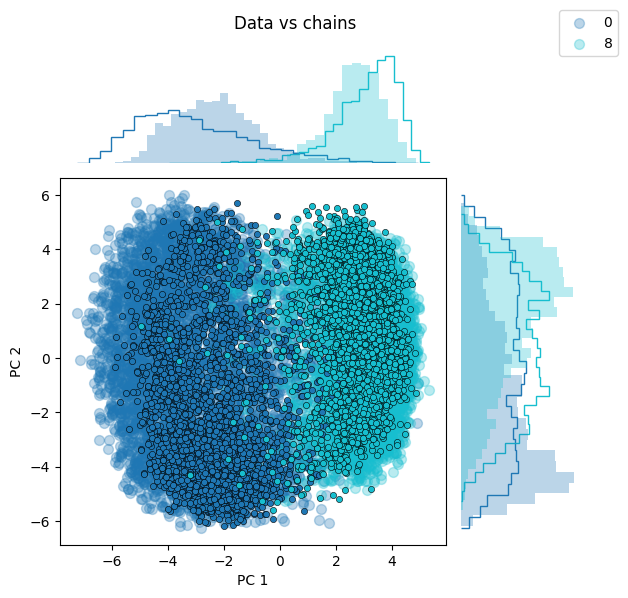

In [5]:
# Project data and chains on the same PCA space
pca = PCA(n_components=2)
data_proj = pca.fit_transform(data.cpu().numpy())
chains_proj = pca.transform(chains["visible"].view(len(chains["visible"]), -1).cpu().numpy())

# Define the colors
unique_labels = np.unique(labels_data)
cmap = plt.get_cmap("tab10", len(unique_labels))
label_to_color = {label.item(): cmap(i) for i, label in enumerate(unique_labels)}

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=chains_proj,
    labels2=labels_chains,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs chains",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

## Sample unconditioned

In [6]:
#chains_init = rbm.init_chains(num_samples=10000)
samples = rbm.sample(gibbs_steps=1000, num_samples=10000)
samples_proj = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
samples_labels = dataset.to_label(samples["label"])

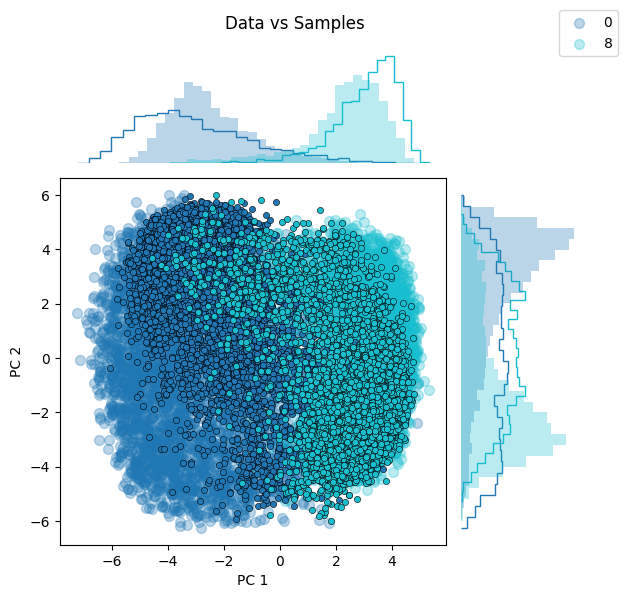

In [7]:
fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=samples_proj,
    labels2=samples_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Samples",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

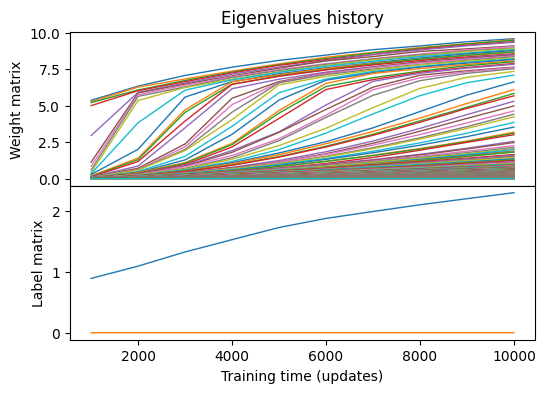

In [8]:
updates, eigenvalues = get_eigenvalues_history(fname_model, target_matrix="weight_matrix", device=device, dtype=dtype)
updates, eigenvalues_labels = get_eigenvalues_history(fname_model, target_matrix="label_matrix", device=device, dtype=dtype)

# Plot the eigenvalues history. first row is the weight matrix, second row is the label matrix.
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={'hspace': 0})
ax[0].plot(updates, eigenvalues, lw=1)
ax[1].plot(updates, eigenvalues_labels, lw=1)
ax[1].set_xlabel("Training time (updates)")
ax[0].set_ylabel("Weight matrix")
ax[1].set_ylabel("Label matrix")
ax[0].set_title("Eigenvalues history");

## Conditioned sampling

In [9]:
rbm.load(fname_model, device=device, dtype=dtype)
cond_chains = rbm.sample_conditioned(
    gibbs_steps=10000,
    targets=dataset.labels_one_hot,
)

In [10]:
cond_chains_proj = pca.transform(cond_chains["visible"].view(len(cond_chains["visible"]), -1).cpu().numpy())
cond_chains_labels = labels_data

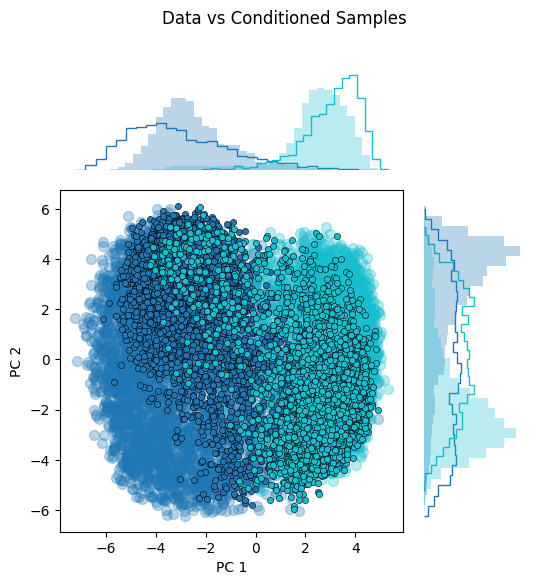

In [11]:
fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=cond_chains_proj,
    labels2=cond_chains_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Conditioned Samples",
    split_labels=True,
)

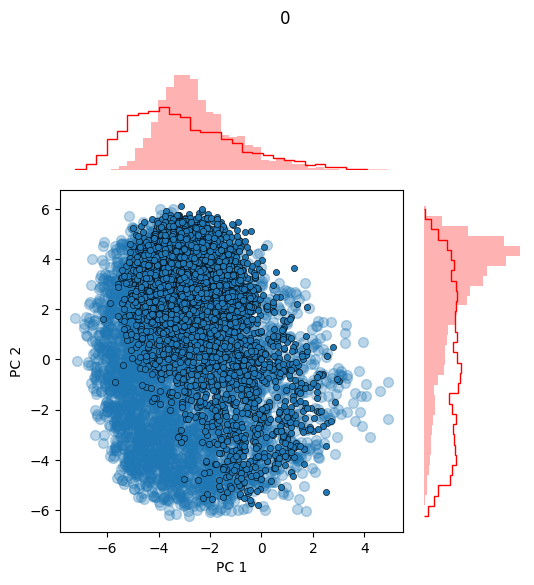

In [12]:
# Plot pca of conditioned chains and data but only one label
label_idx = 0
label = dataset.idx_to_label[label_idx]
mask_data = labels_data == label
mask_gen = cond_chains_labels == label
data_proj_label = data_proj[mask_data]
chains_proj_label = cond_chains_proj[mask_gen]

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj_label,
    labels1=labels_data[mask_data],
    data2=chains_proj_label,
    labels2=cond_chains_labels[mask_gen],
    label_to_color={label: cmap(label_idx)},
    dim1=0,
    dim2=1,
    title=label,
    split_labels=False,
)

## Predict labels of the data

In [14]:
# Train accuracy
predictions = rbm.predict_labels(visible=dataset.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Train accuracy: {accuracy}")

predictions = rbm.predict_labels(visible=dataset_test.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset_test.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Test accuracy: {accuracy}")

Train accuracy: 0.9921944737434387
Test accuracy: 0.9882593750953674


## Importance sampling

In [15]:
from typing import Dict, Tuple

def importance_sampling(
    rbm: annaRBMbin,
    num_samples: int,
    wild_type: torch.Tensor,
    target_label_oh: torch.Tensor,
    ngibbs: int,
    importance_weight: float,
    beta: float = 1.0,
    sigma: float = 1.0,
) -> Dict[str, torch.Tensor]:
    """Perform importance sampling with the RBM conditioned to a target label.

    Args:
        rbm (annaRBMbin): annaRBMbin instance.
        num_samples (int): Number of samples to generate.
        wild_type (torch.Tensor): Wild type sequence.
        target_label_oh (torch.Tensor): One-hot encoded target label.
        ngibbs (int): Number of Gibbs sampling steps.
        importance_weight (float): Importance weight for the wild type.
        beta (float, optional): Controls the relative importance of the generative Hamiltonian. Defaults to 1.0.
        sigma (float, optional): Controls the relative importance of the label Hamiltonian. Defaults to 1.0.

    Returns:
        Dict[str, torch.Tensor]: Generated samples.
    """
    # replicate the wild type sequence
    samples = wild_type.unsqueeze(0).repeat(num_samples, 1)
    
    # modify the visible bias for importance sampling
    rbm_mod = rbm.clone()
    # bias on the wild type sites, accounting for 0-1 variables
    rbm_mod.params["vbias"] += importance_weight * (2 * wild_type - 1)
    
    # rescale the generative hamiltonian by beta
    rbm_mod.params["weight_matrix"] *= beta
    rbm_mod.params["vbias"] *= beta
    rbm_mod.params["hbias"] *= beta
    
    # rescale the label hamiltonian by sigma
    rbm_mod.params["label_matrix"] *= sigma
    rbm_mod.params["lbias"] *= sigma

    # replicate the target label
    target_label_oh = target_label_oh.unsqueeze(0).repeat(num_samples, 1)
    samples = rbm_mod.sample_conditioned(
        gibbs_steps=ngibbs,
        visible=samples,
        beta=1.0,
        targets=target_label_oh
    )
    return samples


def compute_Hdisc(
    rbm: annaRBMbin,
    samples: Dict[str, torch.Tensor],
    target_label_oh: torch.Tensor
) -> torch.Tensor:
    """Computes the Hamiltonian for the discriminative task.

    Args:
        rbm (annaRBMbin): The RBM model.
        samples (Dict[str, torch.Tensor]): The generated samples.
        target_label_oh (torch.Tensor): One-hot encoded target label.

    Returns:
        torch.Tensor: The computed Hamiltonian.
    """
    fields = target_label_oh @ rbm.params["lbias"]
    interactions = (samples["hidden_mag"] @ rbm.params["label_matrix"].T @ target_label_oh)
    return - fields - interactions


def get_energy_contributions(
    rbm: annaRBMbin,
    samples: Dict[str, torch.Tensor],
    target_label_oh: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    # Generative energy
    Hgen = rbm.compute_energy_visibles(
        visible=samples["visible"],
        label=target_label_oh.repeat(len(samples["visible"]), 1)
    )
    # Label probability
    target_label_idx = target_label_oh.argmax(dim=-1)
    p_label = rbm.predict_labels(**samples)[:, target_label_idx]
    return Hgen, p_label

def get_distance_from_wt(
    wt: torch.Tensor,
    samples: Dict[str, torch.Tensor]
) -> torch.Tensor:
    return (samples["visible"] != wt).float().sum(-1)

### Calibration

In [ ]:
import ipywidgets as widgets

# Select a wild type sample and a target label
label_wt_interact = widgets.IntText(min=0, max=9, step=1, value=0, description="WT Label:")
label_target_interact = widgets.IntText(min=0, max=9, step=1, value=8, description="Target Label:")
wt_index_interact = widgets.IntText(min=0, max=100, step=1, value=8, description="WT Index:")

# Generation
importance_weight_interact = widgets.FloatText(min=0, max=1000, step=0.01, value=0.5, description="Lambda:")
num_samples_interact = widgets.IntText(min=1, max=50000, step=1, value=10000, description="Num Samples:")
ngibbs_interact = widgets.IntText(min=1, max=100000, step=1, value=1000, description="N Gibbs:")
beta_interact = widgets.FloatText(min=0, max=2, step=0.01, value=1.0, description="Beta:")

def plot_wt(label_wt, label_target, wt_index):
    wild_type = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_wt][wt_index]
    plt.imshow(wild_type.reshape(28, 28).cpu().numpy(), cmap="gray")
    plt.title(f"Wild Type Digit: {label_wt}, index: {wt_index}")
    plt.axis("off")
    plt.show()

    print(f"Target Digit: {label_target}")
    
    return wild_type


def calibrate_and_plot(importance_weight, num_samples, ngibbs, beta, wild_type, wild_type_data_pca, target_data_pca, label_target_oh):
    samples = importance_sampling(
        rbm=rbm,
        num_samples=num_samples,
        wild_type=wild_type,
        target_label_oh=label_target_oh,
        ngibbs=ngibbs,
        importance_weight=importance_weight,
        beta=beta,
        sigma=1.0,
    )
    distances = get_distance_from_wt(
        wt=wild_type,
        samples=samples,
    )
    
    # project wild type and samples in the PCA
    samples_pca = pca.transform(samples["visible"].cpu().numpy())
    wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.scatter(wild_type_data_pca[:, 0], wild_type_data_pca[:, 1], alpha=0.3, label="WT-like data")
    plt.scatter(target_data_pca[:, 0], target_data_pca[:, 1], alpha=0.5, label="Target-like data")
    plt.scatter(samples_pca[:, 0], samples_pca[:, 1], alpha=0.5, label="Generated samples")
    plt.scatter(wt_pca[:, 0], wt_pca[:, 1], s=100, color='red', marker='d', label="Wild Type")
    plt.title("PCA of Generated Samples")
    plt.xlabel("PC 1")
    plt.ylabel("PC 2")
    plt.legend()
    plt.tight_layout()

    plt.subplot(1, 2, 2)
    plt.hist(distances.cpu().numpy(), bins=30, color='red', alpha=0.7)
    plt.title("Distance from WT Distribution")
    plt.xlabel("Hamming Distance")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    return samples
    
def plot_generated(samples):
    # plot 10 generated mnist samples
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for i, ax in enumerate(axes.flat):
        if i < len(samples["visible_mag"]):
            ax.imshow(samples["visible_mag"][i].reshape(28, 28).cpu().numpy(), cmap="gray")
            ax.set_title(f"Sample {i+1}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def run_all(label_wt, label_target, wt_index, importance_weight, num_samples, ngibbs, beta):
    wild_type = plot_wt(label_wt, label_target, wt_index)
    wild_type_data = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_wt]
    target_data = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_target]
    label_target_oh = dataset.labels_one_hot[dataset.data["label"].to_numpy() == label_target][0]
    
    # pca projection on wild type data and target data 
    wild_type_data_pca = pca.transform(wild_type_data.cpu().numpy())
    target_data_pca = pca.transform(target_data.cpu().numpy())

    samples = calibrate_and_plot(importance_weight, num_samples, ngibbs, beta, wild_type, wild_type_data_pca, target_data_pca, label_target_oh)
    plot_generated(samples)

interaction = widgets.interact(run_all,
    label_wt=label_wt_interact,
    label_target=label_target_interact,
    wt_index=wt_index_interact,
    importance_weight=importance_weight_interact,
    num_samples=num_samples_interact,
    ngibbs=ngibbs_interact,
    beta=beta_interact,
)

interactive(children=(IntText(value=0, description='WT Label:'), IntText(value=8, description='Target Label:')…

<function __main__.run_all(label_wt, label_target, wt_index, importance_weight, num_samples, ngibbs, beta)>

### Parenzio line

In [18]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(
    dataset.data_one_hot.cpu().numpy(),
    dataset.data["label"].to_numpy()
)

train_accuracy = logreg.score(
    dataset.data_one_hot.cpu().numpy(),
    dataset.data["label"].to_numpy()
)

test_accuracy = logreg.score(
    dataset_test.data_one_hot.cpu().numpy(),
    dataset_test.data["label"].to_numpy()
)

print(f"Logistic Regression Train accuracy: {train_accuracy}")
print(f"Logistic Regression Test accuracy: {test_accuracy}")

Logistic Regression Train accuracy: 0.9982085732565579
Logistic Regression Test accuracy: 0.9908116385911179


In [19]:
def get_energy_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    betas = logreg.coef_[idx_label]
    Hdiscr = - samples["visible"].cpu().numpy() @ betas
    return Hdiscr

def get_prob_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    p_label = logreg.predict_proba(samples["visible"].cpu().numpy())[:, idx_label]
    return p_label

In [22]:
lambda_to_distance = {
    0.3: 60,
    0.15: 90,
}

distance_to_energies = {k: {} for k in lambda_to_distance.values()}

ngibbs = 1000
num_samples = 100000
beta = 1.0
sigma = 1.0

wild_type = dataset.data_one_hot[dataset.data["label"].to_numpy() == label_wt_interact.value][wt_index_interact.value]
label_target_oh = dataset.labels_one_hot[dataset.data["label"].to_numpy() == label_target_interact.value][0]

for importance_weight, distance in lambda_to_distance.items():
    print(f"Importance weight: {importance_weight}, Target distance: {distance}")
    samples = importance_sampling(
        rbm=rbm,
        num_samples=num_samples,
        wild_type=wild_type,
        target_label_oh=label_target_oh,
        ngibbs=ngibbs,
        importance_weight=importance_weight,
        beta=beta,
        sigma=sigma,
    )
    distances = get_distance_from_wt(
        wt=wild_type,
        samples=samples,
    )

    # filter for sequences at a target distance
    samples_filtered = {k: v[distances == distance] for k, v in samples.items()}
    print(f"---> Extracted {len(samples_filtered['visible'])} samples at distance {distance}")

    Hgen, p_rbm = get_energy_contributions(
        rbm=rbm,
        samples=samples_filtered,
        target_label_oh=label_target_oh,
    )
    p_lr = get_prob_logreg(samples_filtered, label_target_oh)
    distance_to_energies[distance]["Hgen"] = Hgen.cpu().numpy()
    distance_to_energies[distance]["p_rbm"] = p_rbm.cpu().numpy()
    distance_to_energies[distance]["p_lr"] = p_lr
    distance_to_energies[distance]["samples"] = samples_filtered["visible_mag"].cpu().numpy()

Importance weight: 0.3, Target distance: 60
---> Extracted 2621 samples at distance 60
Importance weight: 0.15, Target distance: 90
---> Extracted 1647 samples at distance 90


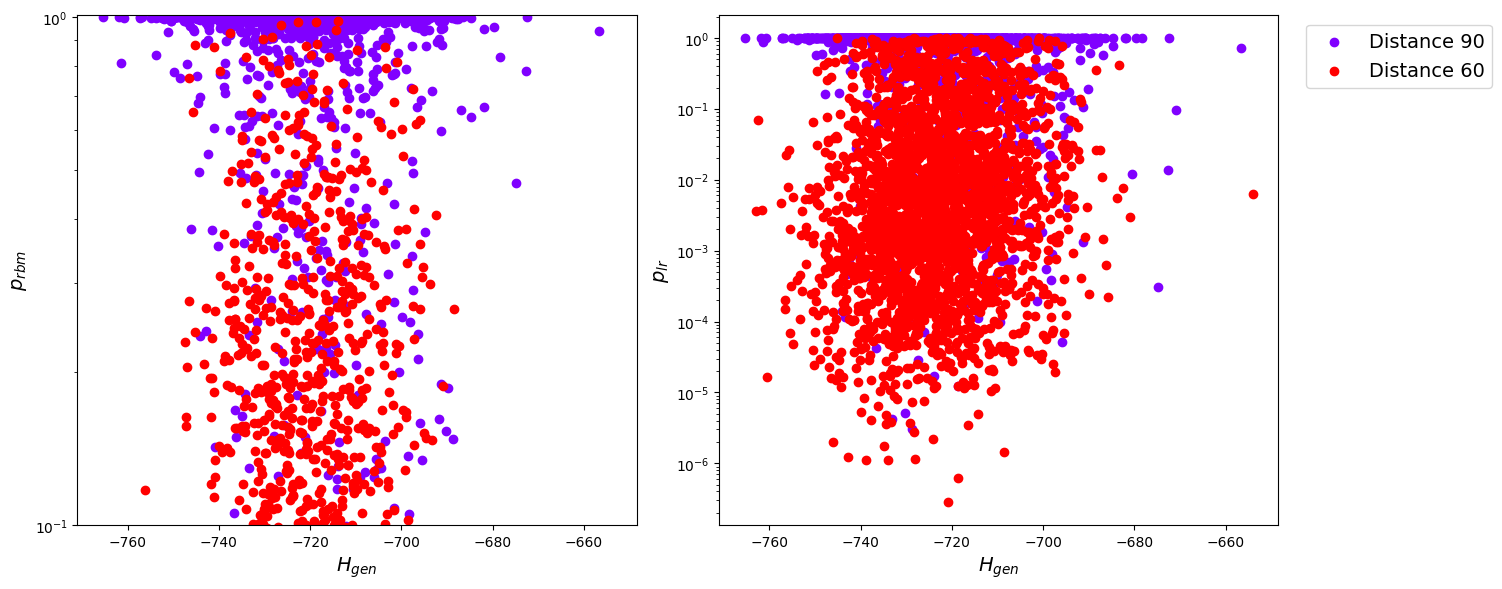

In [23]:
distance_plot = [60, 90]

fontsize = 14
colormap = plt.get_cmap("rainbow", len(distance_plot))

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=100)
ax[0].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[0].set_ylabel(r"$p_{rbm}$", fontsize=fontsize)
ax[0].set_yscale("log")
ax[1].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[1].set_ylabel(r"$p_{lr}$", fontsize=fontsize)
ax[1].set_yscale("log")
ax[0].set_ylim(0.1, 1.01)

for i, distance in enumerate(reversed(distance_plot)):
    ax[0].scatter(distance_to_energies[distance]["Hgen"], distance_to_energies[distance]["p_rbm"],
               color=colormap(i), label=f"Distance {distance}")
    ax[1].scatter(distance_to_energies[distance]["Hgen"], distance_to_energies[distance]["p_lr"],
               color=colormap(i), label=f"Distance {distance}")
ax[1].legend(fontsize=fontsize, bbox_to_anchor=(1.4, 1.0))

fig.tight_layout()

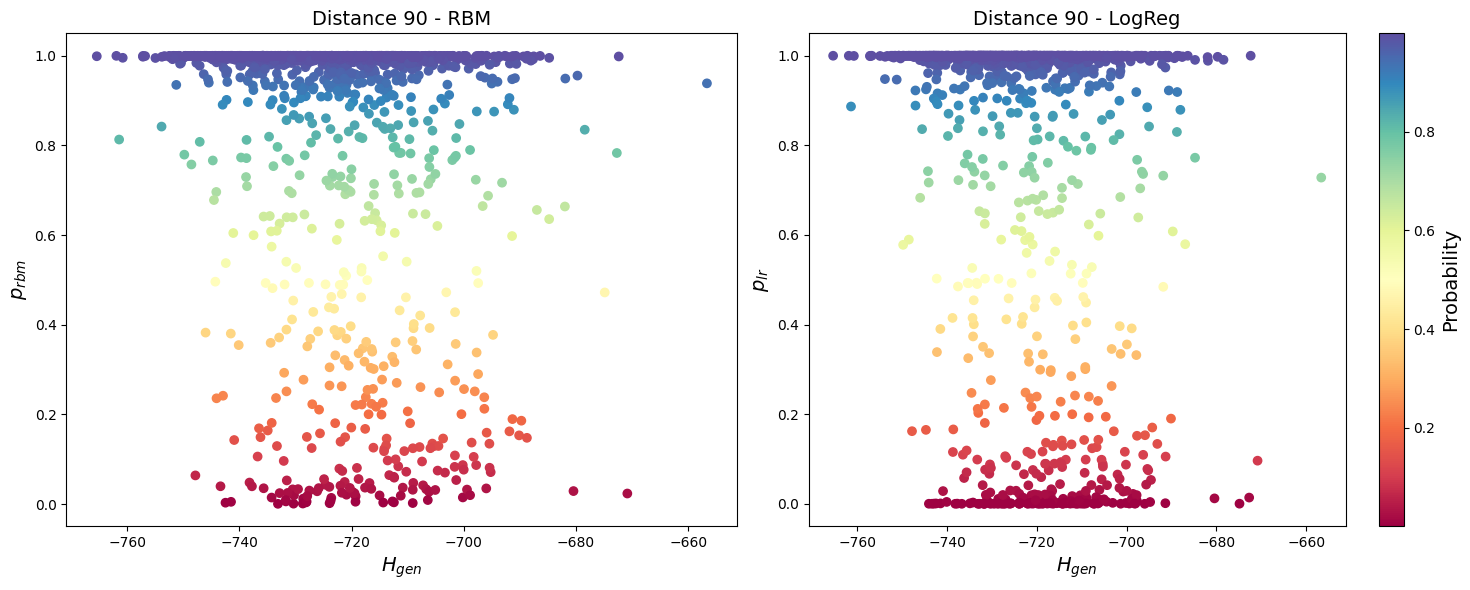

In [24]:
distance_plot = 90
fontsize = 14

Hgen_vals = distance_to_energies[distance_plot]["Hgen"]
p_rbm_vals = distance_to_energies[distance_plot]["p_rbm"]
p_lr_vals = distance_to_energies[distance_plot]["p_lr"]

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=100)
sc = ax[0].scatter(Hgen_vals, p_rbm_vals, c=p_rbm_vals, cmap="Spectral", label=f"Distance {distance_plot}")
ax[0].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[0].set_ylabel(r"$p_{rbm}$", fontsize=fontsize)
ax[0].set_title(f"Distance {distance_plot} - RBM", fontsize=fontsize)

sc = ax[1].scatter(Hgen_vals, p_lr_vals, c=p_lr_vals, cmap="Spectral", label=f"Distance {distance_plot}")
ax[1].set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax[1].set_ylabel(r"$p_{lr}$", fontsize=fontsize)
ax[1].set_title(f"Distance {distance_plot} - LogReg", fontsize=fontsize)

cbar = plt.colorbar(sc, ax=ax[1])
cbar.set_label(r"Probability", fontsize=fontsize)
fig.tight_layout()

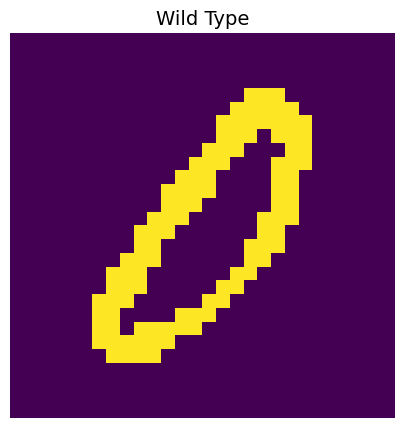

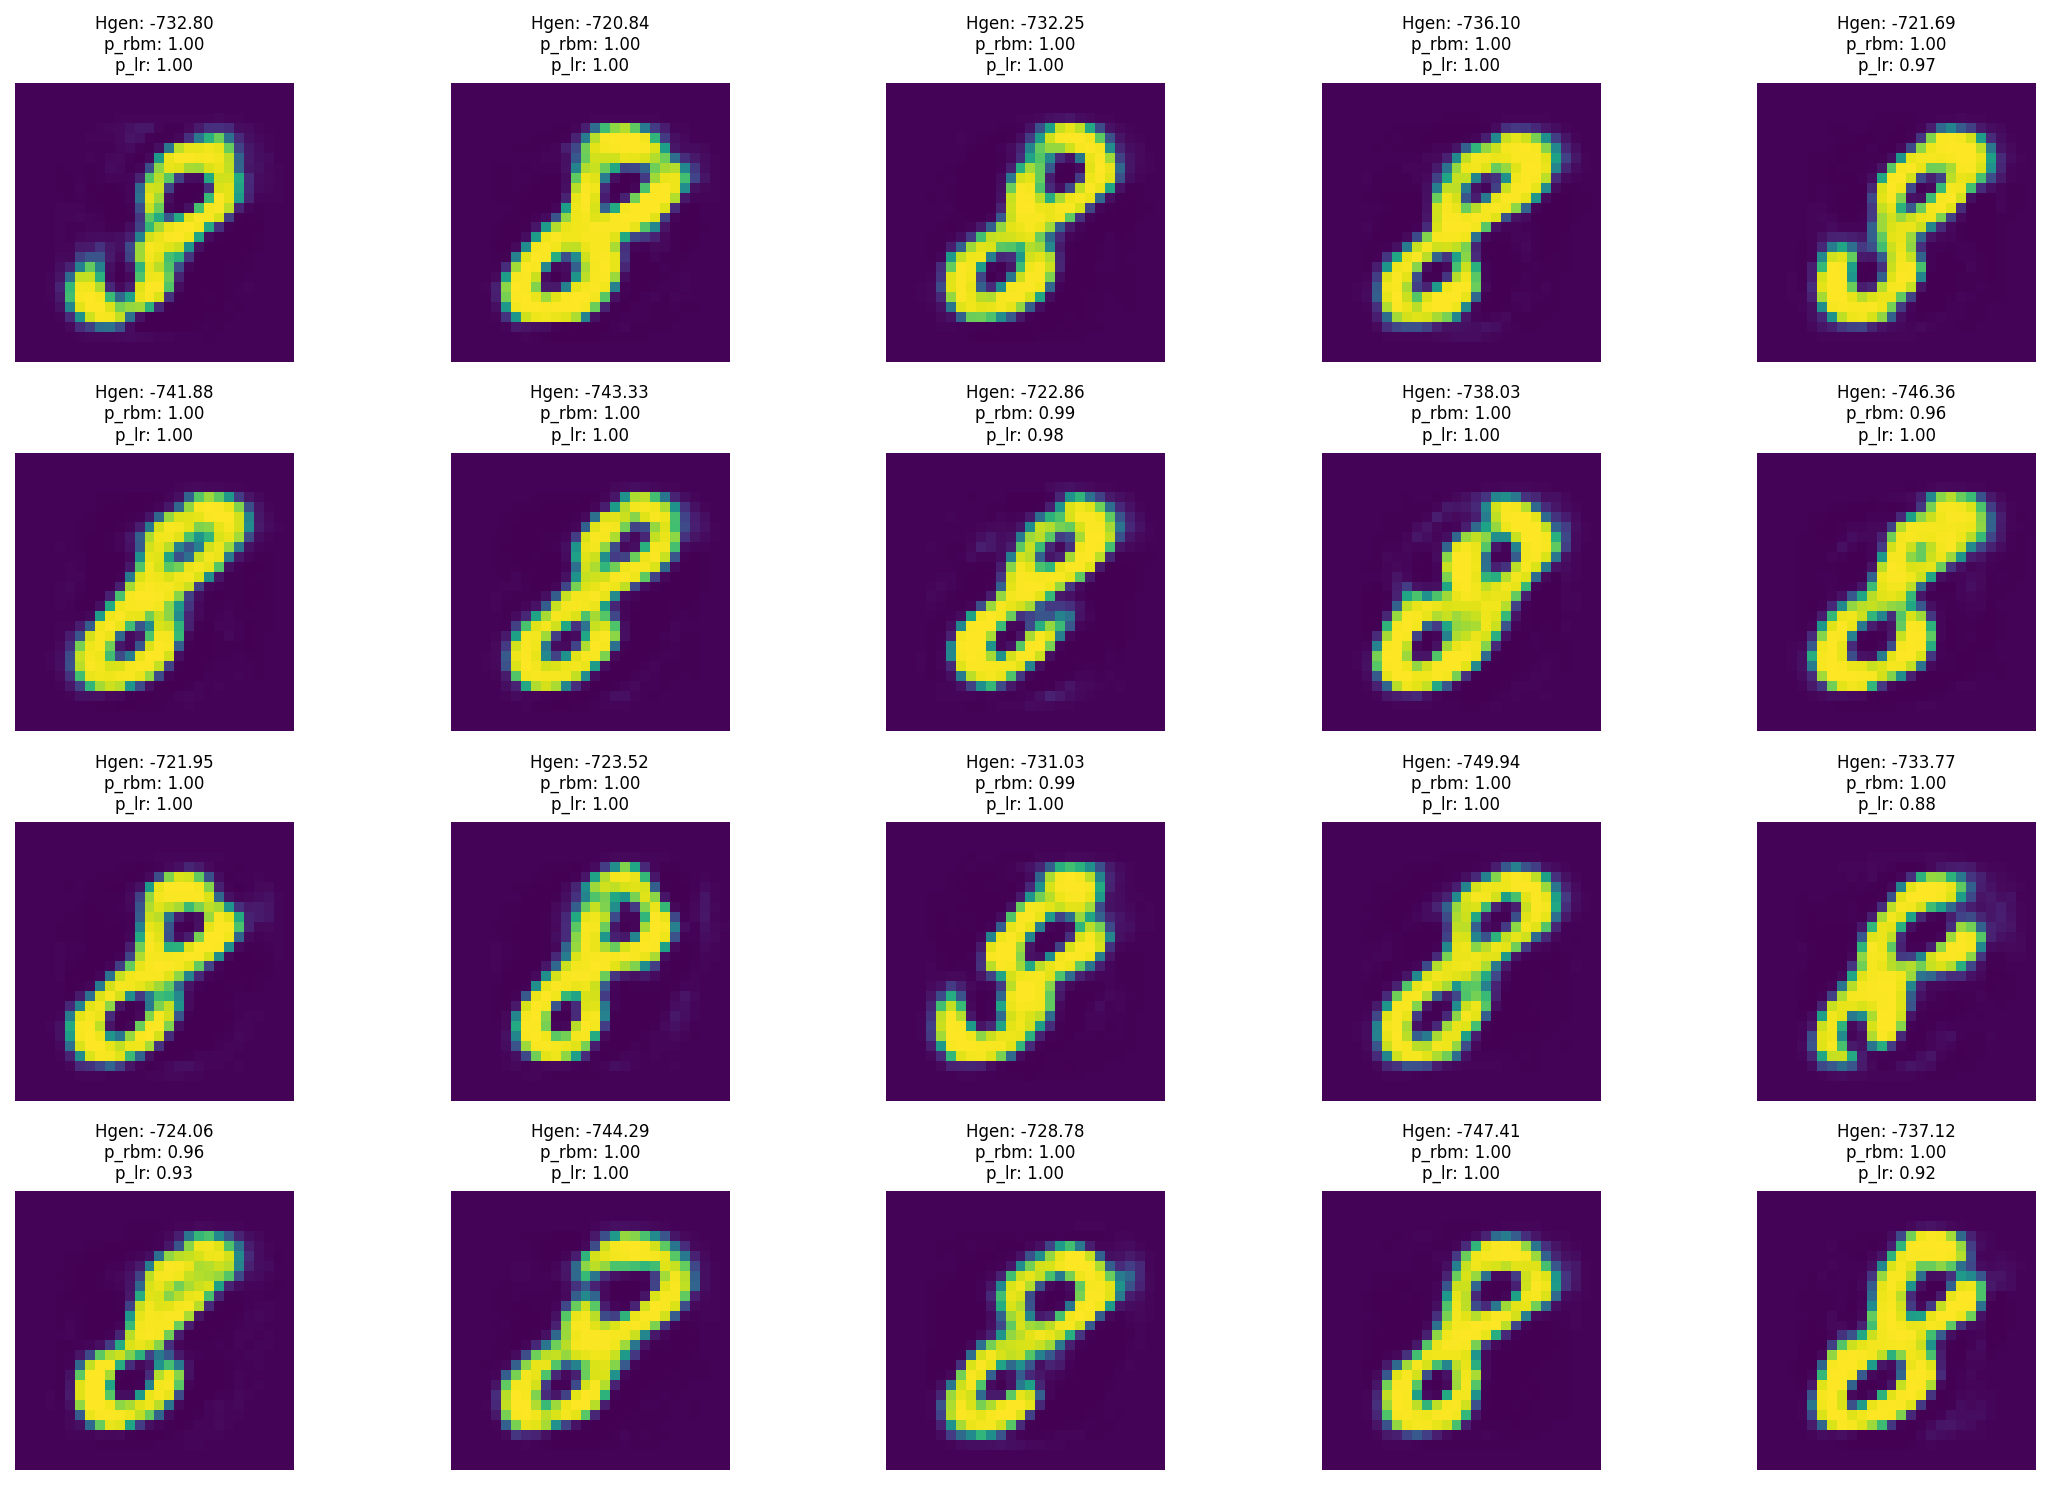

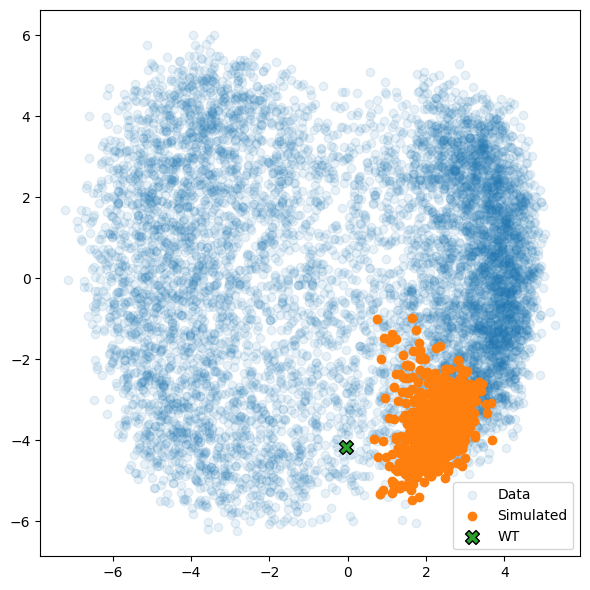

In [25]:
Hgen_max = -720
p_rbm_min = 0.9
p_lr_min = 0.3
distance = 90

mask = (distance_to_energies[distance]["Hgen"] <= Hgen_max) & (distance_to_energies[distance]["p_rbm"] >= p_rbm_min)
#mask = (distance_to_energies[distance]["Hgen"] <= Hgen_max) & (distance_to_energies[distance]["p_lr"] >= p_lr_min)
samples_selected = distance_to_energies[distance]["samples"][mask]
Hgen_selected = distance_to_energies[distance]["Hgen"][mask]
p_rbm_selected = distance_to_energies[distance]["p_rbm"][mask]
p_lr_selected = distance_to_energies[distance]["p_lr"][mask]

fig, ax = plt.subplots(1, 1, figsize=(15, 5), dpi=100)
ax.imshow(wild_type.reshape(28, 28).cpu().numpy(), cmap="viridis")
ax.set_title("Wild Type", fontsize=14)
ax.axis("off")
plt.show()

fig, axes = plt.subplots(4, 5, figsize=(15, 10), dpi=150)
pattern_rbm = rbm.get_pattern(1).cpu().numpy().reshape(28, 28)
pattern_lr = logreg.coef_.reshape(28, 28)
for i, ax in enumerate(axes.flat):
    if i < len(samples_selected):
        im = ax.imshow(samples_selected[i].reshape(28, 28), cmap="viridis", vmin=0, vmax=1)
        ax.set_title(f"Hgen: {Hgen_selected[i]:.2f}\np_rbm: {p_rbm_selected[i]:.2f}\np_lr: {p_lr_selected[i]:.2f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111)
wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())
samples_selected_pca = pca.transform(samples_selected)
ax.scatter(data_proj[:, 0], data_proj[:, 1], alpha=0.1, label="Data")
ax.scatter(samples_selected_pca[:, 0], samples_selected_pca[:, 1], label="Simulated")
ax.scatter(wt_pca[:, 0], wt_pca[:, 1], marker="X", s=100, edgecolors="black", label="WT")
ax.legend()
plt.tight_layout()

In [26]:
label_pattern = widgets.IntText(min=0, max=9, step=1, value=0, description="Pattern:")

def plot_patterns(label_pattern):
    # get RBM patterns
    pattern_rbm = rbm.get_pattern(label_pattern).cpu().numpy().reshape(28, 28)

    # get_logreg_patterns
    pattern_lr = logreg.coef_.reshape(28, 28)
    
    # plot the patterns
    fig, ax = plt.subplots(1, 2, figsize=(8, 4), dpi=100)
    ax[0].imshow(pattern_rbm, cmap="viridis")
    ax[0].set_title("RBM Patterns")
    ax[0].axis("off")
    
    ax[1].imshow(pattern_lr, cmap="viridis")
    ax[1].set_title("Logistic Regression Patterns")
    ax[1].axis("off")
    
    plt.show()

interaction = widgets.interact(plot_patterns, label_pattern=label_pattern)

interactive(children=(IntText(value=0, description='Pattern:'), Output()), _dom_classes=('widget-interact',))

## Sampling Monte Carlo using only the predictor

In [27]:
class Simulator:
    def __init__(self, predictor, predictor_type: str, wild_type: torch.Tensor, importance_weight: float, beta: float):
        self.predictor = predictor
        self.predictor_type = predictor_type
        self.wild_type = wild_type
        self.importance_weight = importance_weight
        self.beta = beta

    def get_energy(self, x: torch.Tensor, target_idx: int):
        energy_is = - self.importance_weight * (x == self.wild_type).float().sum(1).cpu().numpy()
        if self.predictor_type == "rbm":
            mh = self.predictor.sample_hiddens(
                visible=x,
                label=torch.zeros(x.shape[0], self.predictor.num_classes(), device=x.device, dtype=x.dtype),
            )["hidden_mag"]
            energy_pred = - self.beta * (self.predictor.params["lbias"][target_idx] - mh @ self.predictor.params["label_matrix"][target_idx]).cpu().numpy()

        elif self.predictor_type == "logreg":
            # compute the energy using the logistic regression
            betas = logreg.coef_[target_idx]
            bias = logreg.intercept_[target_idx]
            energy_pred = - self.beta * (x.cpu().numpy() @ betas - bias)

        else:
            raise ValueError("predictor_type must be 'rbm' or 'logreg'")
        return energy_is + energy_pred
        
    def mutate(self, x: torch.Tensor):
        # randomly flip one bit. Define for one sample and extend using vmap
        def flip_bit(x):
            x_copy = x.clone()
            idx = torch.randint(0, x.shape[0], (1,))
            x_copy[idx] = 1 - x_copy[idx]
            return x_copy

        return torch.vmap(flip_bit, randomness="different")(x)

    def log_acc_prob(self, x_old: torch.Tensor, x_new: torch.Tensor):
        # Compute the acceptance probability
        energy_old = self.get_energy(x_old, target_idx=0)
        energy_new = self.get_energy(x_new, target_idx=0)
        return (energy_old - energy_new)

    def mcmc(self, num_steps: int, num_samples: int, debug: bool = False):
        x = self.wild_type.unsqueeze(0).repeat(num_samples, 1)
        for _ in range(num_steps):
            x_new = self.mutate(x)
            log_acc = self.log_acc_prob(x, x_new)
            probs = np.log(np.random.rand(num_samples) + 1e-7)
            mask = probs < log_acc
            x[mask] = x_new[mask]
            
        return x

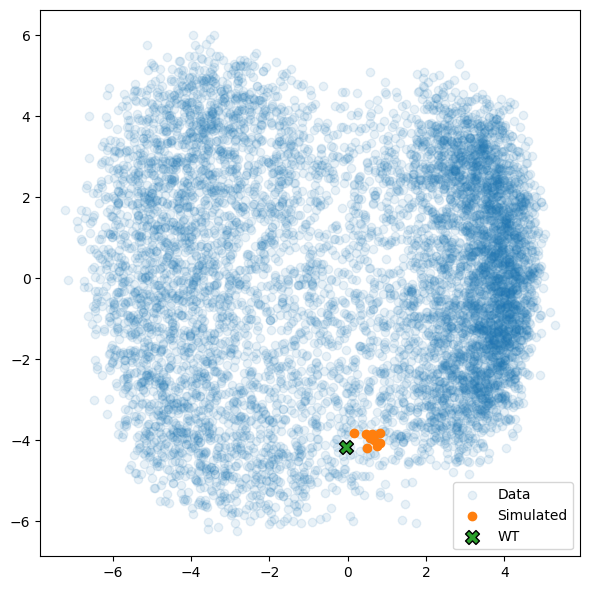

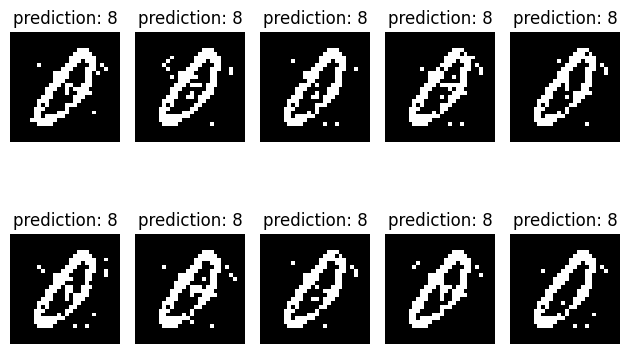

In [28]:
num_steps = 1000
num_samples = 10

beta = 10
importance_weight = 8

simulator = Simulator(predictor=logreg, predictor_type="logreg", wild_type=wild_type, importance_weight=importance_weight, beta=beta)
sim = simulator.mcmc(num_steps=num_steps, num_samples=num_samples)

# pca of the sim
sim_pca = pca.transform(sim.cpu().numpy())

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111)
wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())
ax.scatter(data_proj[:, 0], data_proj[:, 1], alpha=0.1, label="Data")
ax.scatter(sim_pca[:, 0], sim_pca[:, 1], label="Simulated")
ax.scatter(wt_pca[:, 0], wt_pca[:, 1], marker="X", s=100, edgecolors="black", label="WT")
ax.legend()
plt.tight_layout()

# plot 10 mnist sim data
predictions = logreg.predict(sim.cpu().numpy())
fig = plt.figure()
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sim[i].view(28, 28).cpu().numpy(), cmap="gray")
    plt.title(f"prediction: {predictions[i]}")
    plt.axis("off")
plt.tight_layout()

## Populating the $p_{discr}$ vs $E_{gen}$ space

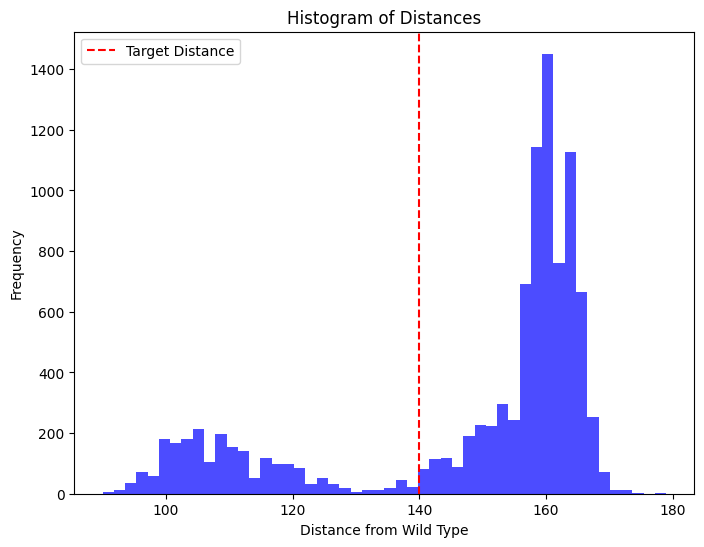

Extracted 35 samples at distance 140


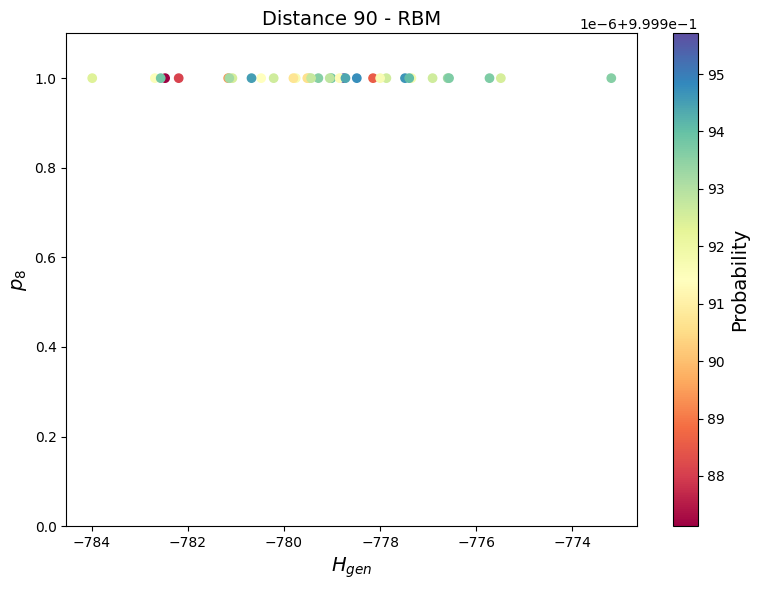

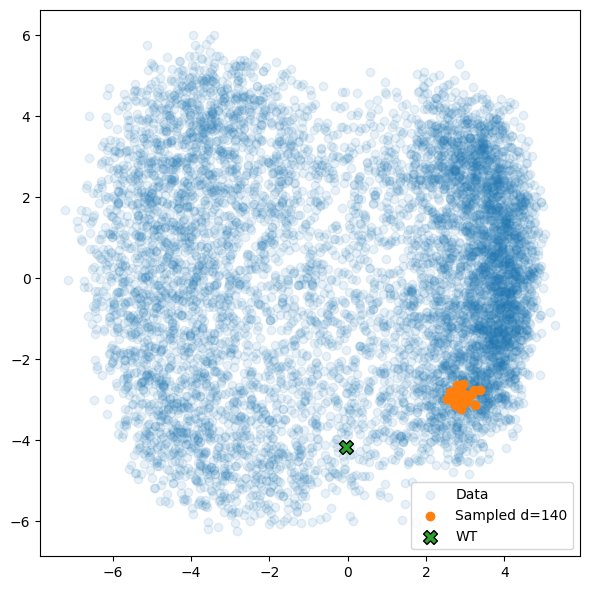

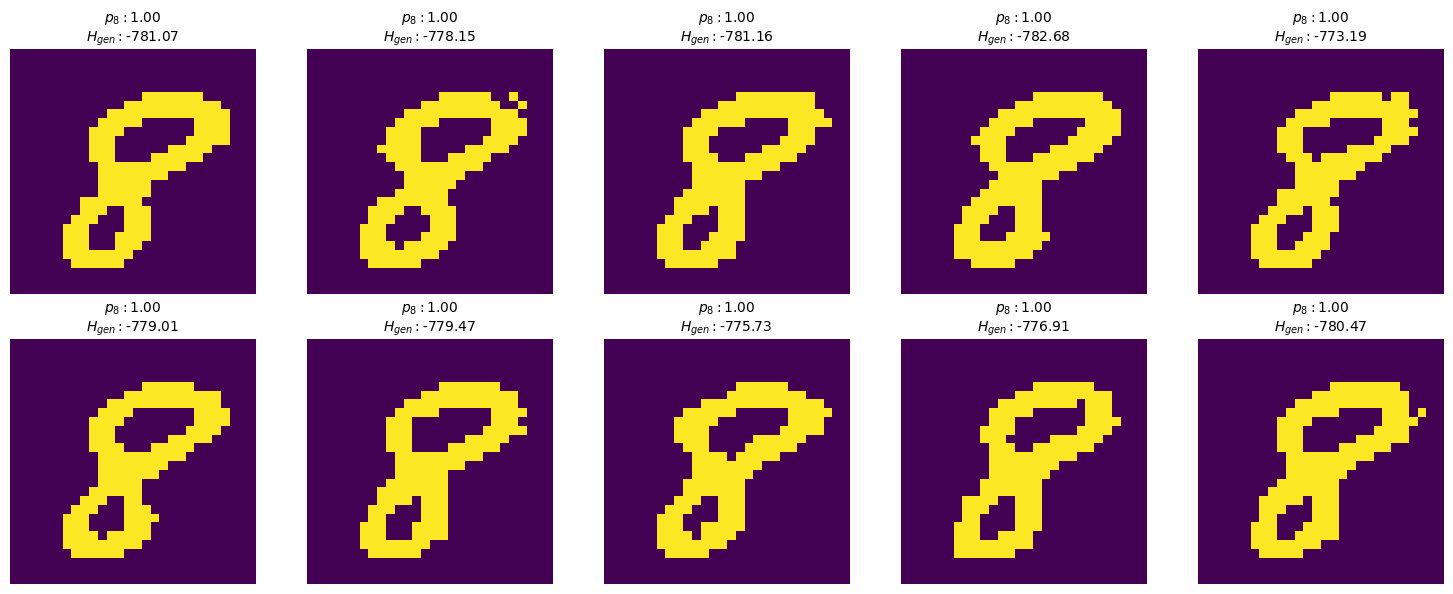

In [30]:
beta = 2.5                  # proxy for E_gen
sigma = 15.0                 # proxy for p_rbm
importance_weight = 0.02     # proxy for the distance from the wild type
num_samples = 10000
ngibbs = 10000
target_distance = 140

samples = importance_sampling(
        rbm=rbm,
        num_samples=num_samples,
        wild_type=wild_type,
        target_label_oh=label_target_oh,
        ngibbs=ngibbs,
        importance_weight=importance_weight,
        beta=beta,
        sigma=sigma,
    )

distances = get_distance_from_wt(
    wt=wild_type,
    samples=samples,
)

# plot histogram of distances
plt.figure(figsize=(8, 6))
plt.hist(distances.cpu().numpy(), bins=50, color='blue', alpha=0.7)
plt.axvline(x=target_distance, color='red', linestyle='--', label='Target Distance')
plt.xlabel('Distance from Wild Type')
plt.ylabel('Frequency')
plt.title('Histogram of Distances')
plt.legend()
plt.show()

# filter for sequences at a target distance
samples_filtered = {k: v[distances == target_distance] for k, v in samples.items()}
print(f"Extracted {len(samples_filtered['visible'])} samples at distance {target_distance}")

Hgen, p_rbm = get_energy_contributions(
    rbm=rbm,
    samples=samples_filtered,
    target_label_oh=label_target_oh,
)

fig, ax = plt.subplots(1, 1, figsize=(8, 6), dpi=100)
sc = ax.scatter(Hgen.cpu().numpy(), p_rbm.cpu().numpy(), c=p_rbm.cpu().numpy(), cmap="Spectral", label=f"Distance {distance_plot}")
ax.set_xlabel(r"$H_{gen}$", fontsize=fontsize)
ax.set_ylabel(r"$p_{8}$", fontsize=fontsize)
ax.set_title(f"Distance {distance_plot} - RBM", fontsize=fontsize)
#ax.set_xlim(-800, -380)
ax.set_ylim(0, 1.1)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(r"Probability", fontsize=fontsize)
fig.tight_layout()

# plot pca of filtered sequences
fig = plt.figure(figsize=(6,6))
samples_filtered_pca = pca.transform(samples_filtered["visible"].cpu().numpy())
plt.scatter(data_proj[:, 0], data_proj[:, 1], alpha=0.1, label="Data")
plt.scatter(samples_filtered_pca[:, 0], samples_filtered_pca[:, 1], label=f"Sampled d={target_distance}")
plt.scatter(wt_pca[:, 0], wt_pca[:, 1], marker="X", s=100, edgecolors="black", label="WT")
plt.legend()
plt.tight_layout()

# plot 10 samples
fig, axs = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axs.flat):
    if i < len(samples_filtered["visible"]):
        ax.imshow(samples_filtered["visible"][i].cpu().numpy().reshape(28, 28), cmap="viridis")
        ax.set_title(r"$p_{8}:$" + f"{p_rbm[i].item():.2f}" + "\n" + r"$H_{gen}:$" + f"{Hgen[i].item():.2f}", fontsize=10)
    ax.axis("off")
plt.tight_layout()

In [ ]:
# Saving the results
fname_output = f"../generated/MNIST08_far0_simulated_beta{beta}_sigma{sigma}_lambda{importance_weight}_d{target_distance}.npz"
np.savez_compressed(
    fname_output,
    samples=samples_filtered["visible"].cpu().numpy(),
    distance=target_distance,
    Hgen=Hgen.cpu().numpy(),
    p_rbm=p_rbm.cpu().numpy()
)

### Populate the plane

In [31]:
bottom_left_name = "../generated/MNIST08_easy0_simulated_beta2.0_sigma0.1_lambda0.08_d60.npz"
upper_left_name = "../generated/MNIST08_easy0_simulated_beta2.0_sigma15.0_lambda0.6_d60.npz"
bottom_right_name = "../generated/MNIST08_easy0_simulated_beta0.1_sigma0.1_lambda25.0_d60.npz"
upper_right_name = "../generated/MNIST08_easy0_simulated_beta0.1_sigma50.0_lambda23.0_d60.npz"

bottom_left_data = np.load(bottom_left_name)
upper_left_data = np.load(upper_left_name)
bottom_right_data = np.load(bottom_right_name)
upper_right_data = np.load(upper_right_name)

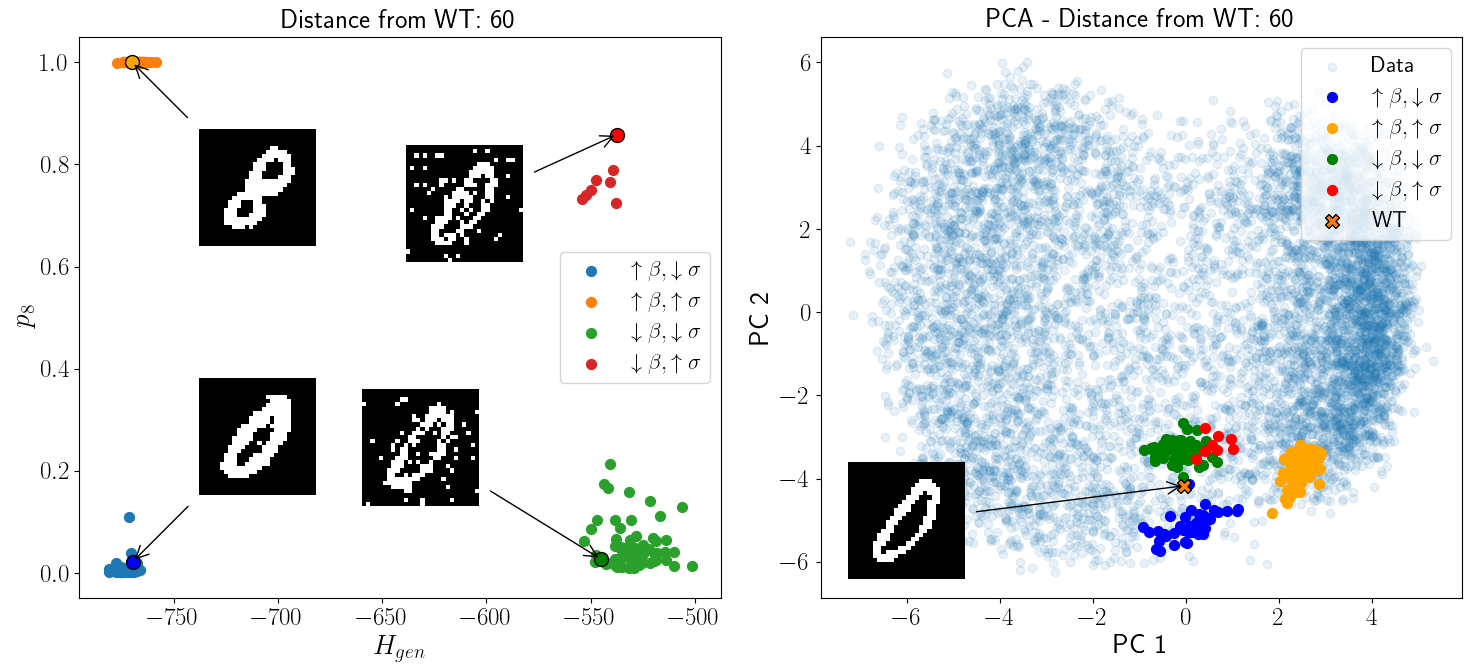

In [32]:
target_distance = 60

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# Use latex
plt.rcParams.update({
    "text.usetex": True,
    "font.size": 16,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "axes.labelsize": 20,
})

# filter data for better visualization
bottom_left_mask = bottom_left_data["p_rbm"] < 0.3
upper_left_mask = upper_left_data["p_rbm"] > 0.8
bottom_right_mask = bottom_right_data["p_rbm"] < 0.3
upper_right_mask = upper_right_data["p_rbm"] > 0.7

fig, ax = plt.subplots(1, 2, figsize=(15,7), dpi=100)

ax[0].scatter(bottom_left_data['Hgen'][bottom_left_mask], bottom_left_data['p_rbm'][bottom_left_mask], s=50, label=r'$\uparrow \beta, \downarrow \sigma$')
ax[0].scatter(upper_left_data['Hgen'][upper_left_mask], upper_left_data['p_rbm'][upper_left_mask], s=50, label=r'$\uparrow \beta, \uparrow \sigma$')
ax[0].scatter(bottom_right_data['Hgen'][bottom_right_mask], bottom_right_data['p_rbm'][bottom_right_mask], s=50, label=r'$\downarrow \beta, \downarrow \sigma$')
ax[0].scatter(upper_right_data['Hgen'][upper_right_mask], upper_right_data['p_rbm'][upper_right_mask], s=50, label=r'$\downarrow \beta, \uparrow \sigma$')

# pick a random point from each set, plot the corresponding mnist image with an arrow
idx_choice = 1
bottom_left_point = bottom_left_data['Hgen'][bottom_left_mask][idx_choice], bottom_left_data['p_rbm'][bottom_left_mask][idx_choice]
upper_left_point = upper_left_data['Hgen'][upper_left_mask][idx_choice], upper_left_data['p_rbm'][upper_left_mask][idx_choice]
bottom_right_point = bottom_right_data['Hgen'][bottom_right_mask][idx_choice], bottom_right_data['p_rbm'][bottom_right_mask][idx_choice]
upper_right_point = upper_right_data['Hgen'][upper_right_mask][idx_choice], upper_right_data['p_rbm'][upper_right_mask][idx_choice]

ax[0].scatter(*bottom_left_point, color='blue', edgecolors='black', s=100)
ax[0].scatter(*upper_left_point, color='orange', edgecolors='black', s=100)
ax[0].scatter(*bottom_right_point, color='green', edgecolors='black', s=100)
ax[0].scatter(*upper_right_point, color='red', edgecolors='black', s=100)

bottom_left_image = bottom_left_data['samples'][bottom_left_mask][idx_choice].reshape(28, 28)
upper_left_image = upper_left_data['samples'][upper_left_mask][idx_choice].reshape(28, 28)
bottom_right_image = bottom_right_data['samples'][bottom_right_mask][idx_choice].reshape(28, 28)
upper_right_image = upper_right_data['samples'][upper_right_mask][idx_choice].reshape(28, 28)
wild_type_image = wild_type.reshape(28, 28).cpu().numpy()

bottom_left_imagebox = OffsetImage(bottom_left_image, zoom=3, cmap="grey")
upper_left_imagebox = OffsetImage(upper_left_image, zoom=3, cmap="grey")
bottom_right_imagebox = OffsetImage(bottom_right_image, zoom=3, cmap="grey")
upper_right_imagebox = OffsetImage(upper_right_image, zoom=3, cmap="grey")
wild_type_imagebox = OffsetImage(wild_type_image, zoom=3, cmap="grey")

bottom_left_ab = AnnotationBbox(
    bottom_left_imagebox,
    bottom_left_point,
    frameon=False,
    xybox=(90, 90),            # offset of the image in pixels
    xycoords="data",
    boxcoords="offset points",
    arrowprops=dict(arrowstyle="->", color='black')
)

upper_left_ab = AnnotationBbox(
    upper_left_imagebox,
    upper_left_point,
    frameon=False,
    xybox=(90, -90),            # offset of the image in pixels
    xycoords="data",
    boxcoords="offset points",
    arrowprops=dict(arrowstyle="->", color='black')
)

bottom_right_ab = AnnotationBbox(
    bottom_right_imagebox,
    bottom_right_point,
    frameon=False,
    xybox=(-130, 80),            # offset of the image in pixels
    xycoords="data",
    boxcoords="offset points",
    arrowprops=dict(arrowstyle="->", color='black')
)

upper_right_ab = AnnotationBbox(
    upper_right_imagebox,
    upper_right_point,
    frameon=False,
    xybox=(-110, -50),            # offset of the image in pixels
    xycoords="data",
    boxcoords="offset points",
    arrowprops=dict(arrowstyle="->", color='black')
)


ax[0].add_artist(bottom_left_ab)
ax[0].add_artist(upper_left_ab)
ax[0].add_artist(bottom_right_ab)
ax[0].add_artist(upper_right_ab)

ax[0].set_xlabel(r"$H_{gen}$")
ax[0].set_ylabel(r"$p_{8}$")
ax[0].set_title(f"Distance from WT: {target_distance}")
ax[0].legend()


bottom_left_pca = pca.transform(bottom_left_data['samples'][bottom_left_mask])
upper_left_pca = pca.transform(upper_left_data['samples'][upper_left_mask])
bottom_right_pca = pca.transform(bottom_right_data['samples'][bottom_right_mask])
upper_right_pca = pca.transform(upper_right_data['samples'][upper_right_mask])


ax[1].scatter(data_proj[:, 0], data_proj[:, 1], alpha=0.1, label="Data")
ax[1].scatter(bottom_left_pca[:, 0], bottom_left_pca[:, 1], s=50, color="blue", label=r'$\uparrow \beta, \downarrow \sigma$')
ax[1].scatter(upper_left_pca[:, 0], upper_left_pca[:, 1], s=50, color="orange", label=r'$\uparrow \beta, \uparrow \sigma$')
ax[1].scatter(bottom_right_pca[:, 0], bottom_right_pca[:, 1], s=50, color="green", label=r'$\downarrow \beta, \downarrow \sigma$')
ax[1].scatter(upper_right_pca[:, 0], upper_right_pca[:, 1], s=50, color="red", label=r'$\downarrow \beta, \uparrow \sigma$')
ax[1].scatter(wt_pca[:, 0], wt_pca[:, 1], marker="X", s=100, edgecolors="black", label="WT")
ax[1].set_xlabel("PC 1")
ax[1].set_ylabel("PC 2")
ax[1].set_title(f"PCA - Distance from WT: {target_distance}")
ax[1].legend(loc="upper right")

wild_type_ab = AnnotationBbox(
    wild_type_imagebox,
    wt_pca[0],
    frameon=False,
    xybox=(-200, -25),            # offset of the image in pixels
    xycoords="data",
    boxcoords="offset points",
    arrowprops=dict(arrowstyle="->", color='black')
)
ax[1].add_artist(wild_type_ab)

plt.tight_layout()
plt.show()